# 03 · Convolutional neural network

This notebook trains a CNN on the 28 × 28 images, evaluates it on the test split, and inspects its learning curves and errors.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src.data import load_emnist
from src.preprocessing import preprocess_images
from src.models import create_cnn

I0000 00:00:1790112579.576143  117438 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790112579.610452  117438 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790112580.889440  117438 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Load and prepare images

The images are scaled to 0–1 and given a channel dimension for the convolutional layers. The labels remain integer digits for sparse categorical cross-entropy.


In [2]:
X_train, y_train, writers_train, X_test, y_test, writers_test = load_emnist()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (240000, 28, 28)
y_train: (240000,)
X_test: (40000, 28, 28)
y_test: (40000,)


In [3]:
X_train = preprocess_images(X_train)
X_test = preprocess_images(X_test)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("dtype:", X_train.dtype)
print("range:", X_train.min(), X_train.max())

X_train: (240000, 28, 28, 1)
X_test: (40000, 28, 28, 1)
dtype: float32
range: 0.0 1.0


## Build and train the CNN

The shared model builder defines the convolution, pooling, dense, and dropout layers. The following cells compile and train that model, then evaluate the saved test split.


In [4]:
cnn = create_cnn()

cnn.summary()

W0000 00:00:1790112583.888248  117438 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
history = cnn.fit(
    X_train,
    y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    verbose=1
)

Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9604 - loss: 0.1329 - val_accuracy: 0.9893 - val_loss: 0.0349
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.9865 - loss: 0.0480 - val_accuracy: 0.9914 - val_loss: 0.0273
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9898 - loss: 0.0366 - val_accuracy: 0.9932 - val_loss: 0.0241
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9912 - loss: 0.0317 - val_accuracy: 0.9931 - val_loss: 0.0234
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.9926 - loss: 0.0264 - val_accuracy: 0.9945 - val_loss: 0.0197
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9933 - loss: 0.0235 - val_accuracy: 0.9943 - val_loss: 0.0219
Epoch 7/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9944 - loss: 0.0201 - val_accuracy: 0.9948 - val_loss: 0.0213
Epoch 8/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9948 -

In [7]:
test_loss, test_accuracy = cnn.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9956 - loss: 0.0213
Test loss: 0.0213
Test accuracy: 0.9956


## Review training curves

Compare training and validation accuracy and loss across epochs. A widening gap can indicate overfitting.


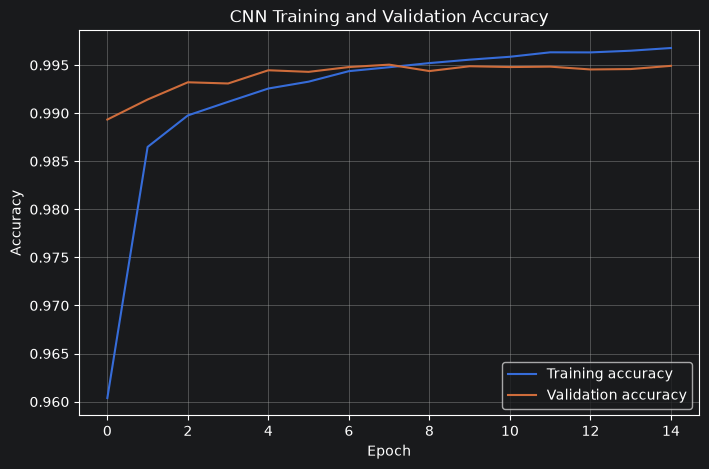

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

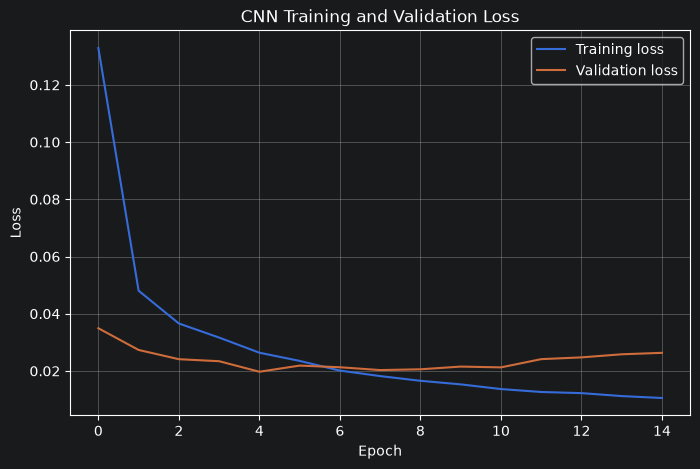

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

## Inspect predictions and errors

The next cells compare predicted digits with the labels, display sample predictions and mistakes, and summarize per-class performance.


In [10]:
y_probability = cnn.predict(X_test, batch_size=128)

y_pred = np.argmax(y_probability, axis=1)

print("Predictions:", y_pred.shape)
print(y_pred[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Predictions: (40000,)
[0 9 7 9 2 2 3 1 0 0 6 4 9 3 8 2 0 8 2 0]


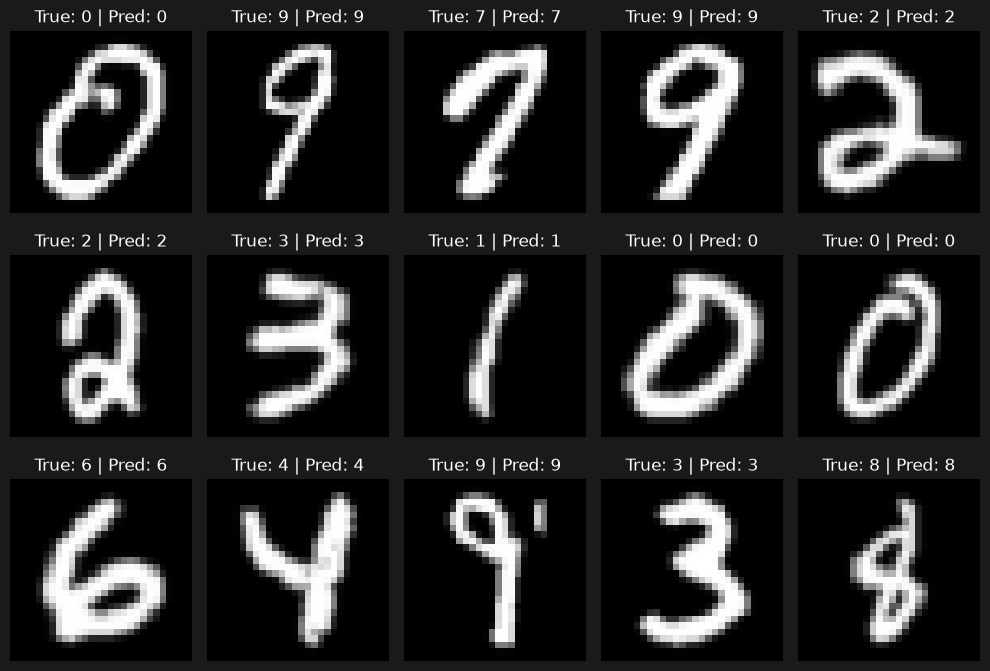

In [11]:
fig, axes = plt.subplots(3, 5, figsize=(10, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i].squeeze(), cmap="gray")
    ax.set_title(
        f"True: {y_test[i]} | Pred: {y_pred[i]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
misclassified = np.where(y_pred != y_test)[0]

print("Misclassified:", len(misclassified))
print(
    "Error rate:",
    len(misclassified) / len(y_test)
)

Misclassified: 176
Error rate: 0.0044


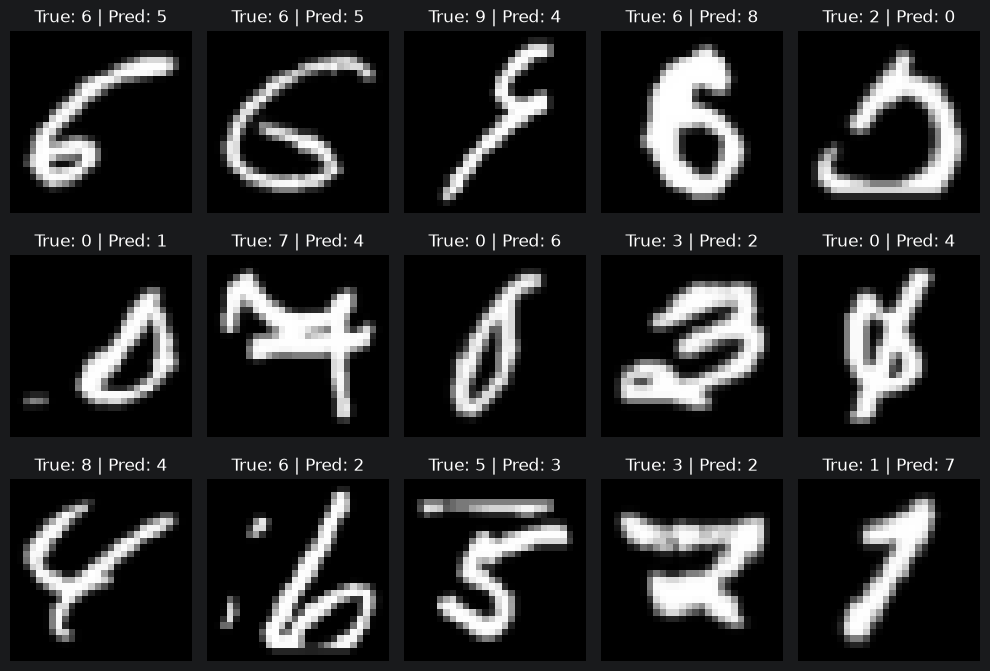

In [13]:
fig, axes = plt.subplots(3, 5, figsize=(10, 7))

for i, ax in enumerate(axes.flat):
    idx = misclassified[i]

    ax.imshow(
        X_test[idx].squeeze(),
        cmap="gray"
    )

    ax.set_title(
        f"True: {y_test[idx]} | Pred: {y_pred[idx]}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
cnn.save("../models/cnn_baseline.keras")

In [15]:
print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9977    0.9968    0.9972      4000
           1     0.9992    0.9962    0.9977      4000
           2     0.9940    0.9955    0.9948      4000
           3     0.9928    0.9962    0.9945      4000
           4     0.9950    0.9958    0.9954      4000
           5     0.9967    0.9925    0.9946      4000
           6     0.9963    0.9972    0.9968      4000
           7     0.9958    0.9960    0.9959      4000
           8     0.9952    0.9945    0.9949      4000
           9     0.9933    0.9952    0.9943      4000

    accuracy                         0.9956     40000
   macro avg     0.9956    0.9956    0.9956     40000
weighted avg     0.9956    0.9956    0.9956     40000



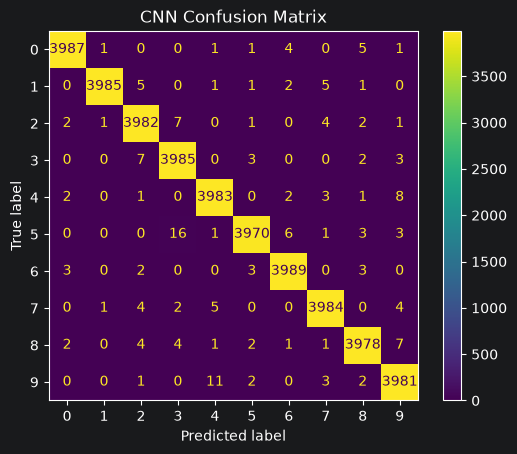

In [16]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot()
plt.title("CNN Confusion Matrix")
plt.show()

## Results

The saved evaluation reports **99.56%** test accuracy and **0.0213** test loss. It misclassified 176 of 40,000 test images (an error rate of **0.44%**). The confusion matrix and report show which digits account for those errors.
